# Validação do token de material pela composição química

Este notebook testa se o espaço latente do `MaterialEncoder` (tokenização por caracteres) reflete a composição química real dos materiais, e depois estuda a **concatenação** embedding + composição química.

**Roteiro**
1. Carrega composição (intervalos) e embeddings; alinha os materiais pelo nome.
2. Matrizes de similaridade: química (IoU de intervalos e cosseno dos pontos médios) e embedding (cosseno, cosseno centralizado, euclidiana).
3. Validação quantitativa: teste de Mantel (correlação de Spearman entre matrizes, com permutação), sobreposição de k vizinhos e *probe* (prever a química a partir do embedding, leave-one-out).
4. Estudo de concatenação: `Z(w) = [√(1-w)·emb_z | √(w)·quim_z]`, varrendo `w`, e exportação do vetor concatenado.
5. Comparação das métricas dos modelos treinados (sem token, token, interação, interação_g).

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from scipy.stats import spearmanr, rankdata
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import LeaveOneOut, cross_val_predict

warnings.filterwarnings("ignore")
RNG = np.random.default_rng(42)

# ---------------- Configuração ----------------
BASE = r"C:\Users\Workstation\Documents\GitHub\welding-optuna-pytorch"
PATH_QUIMICA = os.environ.get("PATH_QUIMICA", BASE + r"\data\material_apoio\comp test.xlsx")
PATH_EMB     = os.environ.get("PATH_EMB",     BASE + r"\embeddings_filtered.csv")
PATH_SAIDA   = os.environ.get("PATH_SAIDA",   "embeddings_concat_quimica.csv")
PATH_ARTEFATO = os.environ.get("PATH_ARTEFATO", "concat_quimica_artefatos.joblib")

ELEMENTOS = ["C", "Si", "Mn", "P", "S", "N", "Cr", "Mo", "Cu", "V", "Al", "Ni", "Ti", "Co"]
K_LIST = [1, 3, 5]                      # vizinhos avaliados
N_PERM = 5000                           # permutações do teste de Mantel
N_PERM_PROBE = 100                      # permutações do probe
PESOS = np.round(np.linspace(0, 1, 11), 2)   # w: fração de variância vinda da química
W_ESCOLHIDO = 0.5                       # w usado na exportação

## 1. Funções auxiliares

Diferenças em relação ao notebook original:
- intervalos abertos (`≥ x`) recebem um teto finito (2× o maior limite do elemento). Antes, `inf/inf` gerava `NaN` na similaridade;
- valores pontuais (ex.: `0.08`) são alargados por uma pequena folga (0,5% do teto do elemento), senão um ponto dentro de uma faixa dava similaridade 0;
- `1e-05` e similares são lidos como número antes de tentar separar por `-`.

In [2]:
def normalizar_nome(s):
    return re.sub(r"\s+", " ", str(s)).strip().upper()

def extrair_intervalo(valor):
    if pd.isna(valor):
        return None
    s = str(valor).replace(",", ".").strip()
    if s in ("", "-", "–", "—"):
        return None
    try:
        x = float(s)
        return (x, x)
    except ValueError:
        pass
    try:
        if s[0] in "≤<":
            return (0.0, float(s.lstrip("≤<= ")))
        if s[0] in "≥>":
            return (float(s.lstrip("≥>= ")), float("inf"))
        partes = re.split(r"\s*[-–—]\s*", s)
        if len(partes) == 2:
            return (float(partes[0]), float(partes[1]))
    except ValueError:
        pass
    return None

def preparar_intervalos(df, elementos):
    ints, teto_el = {}, {}
    for el in elementos:
        col = df[el].apply(extrair_intervalo)
        finitos = [v for iv in col if iv is not None for v in iv if np.isfinite(v)]
        teto = max(finitos) if finitos else 1.0
        teto = teto if teto > 0 else 1.0
        ints[el] = [None if iv is None else (iv[0], 2 * teto if np.isinf(iv[1]) else iv[1]) for iv in col]
        teto_el[el] = teto
    return ints, teto_el

def sim_iou(a, b, eps):
    if a[1] == a[0]: a = (a[0] - eps, a[1] + eps)
    if b[1] == b[0]: b = (b[0] - eps, b[1] + eps)
    inter = max(0.0, min(a[1], b[1]) - max(a[0], b[0]))
    if inter == 0: return 0.0
    uniao = max(1e-9, max(a[1], b[1]) - min(a[0], b[0]))
    return inter / uniao

def matriz_iou(ints, teto_el, elementos):
    n = len(ints[elementos[0]])
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            vals = []
            for el in elementos:
                a, b = ints[el][i], ints[el][j]
                if a is not None and b is not None:
                    vals.append(sim_iou(a, b, 0.005 * teto_el[el]))
            M[i, j] = np.mean(vals) if vals else 0.0
    return M

def vetor_ponto_medio(ints, elementos):
    n = len(ints[elementos[0]])
    X = np.full((n, len(elementos)), np.nan)
    for k, el in enumerate(elementos):
        for i, iv in enumerate(ints[el]):
            if iv is not None:
                X[i, k] = (iv[0] + iv[1]) / 2
    return pd.DataFrame(X, columns=elementos)

def cos_matrix(X):
    Xn = X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-12, None)
    return Xn @ Xn.T

def euc_matrix(X):
    d = X[:, None, :] - X[None, :, :]
    return np.sqrt((d ** 2).sum(-1))

def tri(M):
    return M[np.triu_indices_from(M, k=1)]

def mantel(A, B, n_perm=N_PERM):
    a = rankdata(tri(A))
    obs = np.corrcoef(a, rankdata(tri(B)))[0, 1]
    n, cont = len(A), 0
    for _ in range(n_perm):
        p = RNG.permutation(n)
        r = np.corrcoef(a, rankdata(tri(B[np.ix_(p, p)])))[0, 1]
        cont += abs(r) >= abs(obs)
    return obs, (cont + 1) / (n_perm + 1)

def vizinhos(S, k):
    S = S.astype(float).copy()
    np.fill_diagonal(S, -np.inf)
    return np.argsort(-S, axis=1, kind="stable")[:, :k]

def overlap_knn(S_ref, S_alt, k):
    a, b = vizinhos(S_ref, k), vizinhos(S_alt, k)
    return float(np.mean([len(set(a[i]) & set(b[i])) / k for i in range(len(a))]))

## 2. Carga e alinhamento dos materiais

In [3]:
quim = pd.read_excel(PATH_QUIMICA)
if "material" not in quim.columns:
    quim = quim.rename(columns={quim.columns[0]: "material"})
quim = quim.dropna(subset=["material"])

elementos = [e for e in ELEMENTOS if e in quim.columns]
faltando = sorted(set(ELEMENTOS) - set(elementos))
if faltando:
    print("Elementos ausentes na planilha (ignorados):", faltando)

emb = pd.read_csv(PATH_EMB)
colunas_vetor = [c for c in emb.columns if c != "material" and pd.api.types.is_numeric_dtype(emb[c])]

quim["_k"] = quim["material"].map(normalizar_nome)
emb["_k"] = emb["material"].map(normalizar_nome)
for nome, d in (("química", quim), ("embeddings", emb)):
    dup = d["_k"].duplicated().sum()
    if dup:
        print(f"Aviso: {dup} nomes duplicados em {nome}; mantendo o primeiro de cada.")
quim = quim.drop_duplicates("_k")
emb = emb.drop_duplicates("_k")

comuns = [k for k in emb["_k"] if k in set(quim["_k"])]
so_emb = sorted(set(emb["_k"]) - set(quim["_k"]))
so_quim = sorted(set(quim["_k"]) - set(emb["_k"]))
print(f"Materiais em comum: {len(comuns)} | só nos embeddings: {len(so_emb)} | só na química: {len(so_quim)}")
if so_emb:  print("  só nos embeddings:", so_emb)
if so_quim: print("  só na química:", so_quim)
assert len(comuns) >= 6, "Poucos materiais em comum: confira a normalização dos nomes."

quim = quim.set_index("_k").loc[comuns].reset_index(drop=True)
emb = emb.set_index("_k").loc[comuns].reset_index(drop=True)
materiais = emb["material"].tolist()
E = emb[colunas_vetor].to_numpy(float)
N = len(materiais)
print(f"N = {N} materiais | dimensão do embedding = {E.shape[1]}")

Aviso: 1 nomes duplicados em química; mantendo o primeiro de cada.
Materiais em comum: 7 | só nos embeddings: 0 | só na química: 7
  só na química: ['A333 GR1', 'A333 GR10', 'A333 GR11', 'A333 GR3', 'A333 GR4', 'A333 GR7', 'A333 GR9']
N = 7 materiais | dimensão do embedding = 16


## 3. Matrizes de similaridade

In [5]:
# --- Química ---
ints, teto_el = preparar_intervalos(quim, elementos)
S_iou = matriz_iou(ints, teto_el, elementos)

C_mid = vetor_ponto_medio(ints, elementos)
medianas = C_mid.median()
C_imp = C_mid.fillna(medianas)
elementos_ok = [e for e in elementos if C_imp[e].std() > 0]     # remove elementos sem variação
sc_quim = StandardScaler().fit(C_imp[elementos_ok])
C_z = sc_quim.transform(C_imp[elementos_ok])
S_quim_cos = cos_matrix(C_z)

# --- Embeddings ---
S_emb_cos   = cos_matrix(E)                         # como no notebook original
S_emb_cos_c = cos_matrix(E - E.mean(axis=0))        # centralizado (remove o viés comum a todos os tokens)
S_emb_euc   = -euc_matrix(E)                        # negativo da distância: maior = mais parecido

off = ~np.eye(N, dtype=bool)
print(f"Elementos usados no vetor químico: {elementos_ok}")
print(f"Cosseno médio entre materiais distintos (embedding bruto): {S_emb_cos[off].mean():.3f}")
print("  -> valor alto (>0,8) indica anisotropia: o cosseno bruto discrimina pouco; compare com o centralizado.")

Elementos usados no vetor químico: ['C', 'Si', 'Mn', 'P', 'S', 'N', 'Cr', 'Mo', 'Cu', 'V', 'Ni']
Cosseno médio entre materiais distintos (embedding bruto): 0.022
  -> valor alto (>0,8) indica anisotropia: o cosseno bruto discrimina pouco; compare com o centralizado.


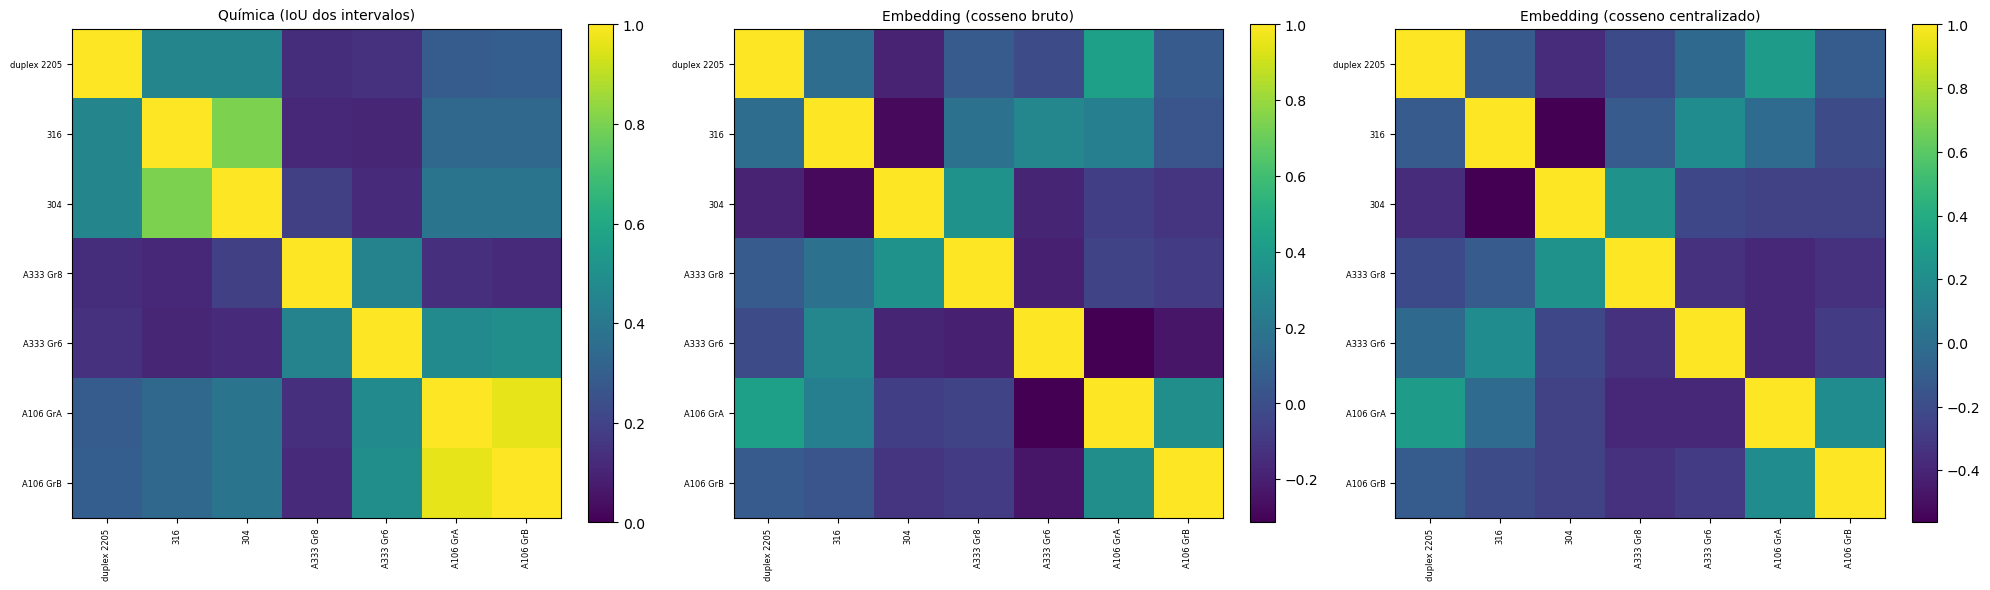

In [6]:
ordem = leaves_list(linkage(squareform(1 - S_quim_cos, checks=False).clip(0), "average"))
nomes_o = [materiais[i] for i in ordem]

def heat(ax, M, titulo, vmin=None, vmax=None):
    im = ax.imshow(M[np.ix_(ordem, ordem)], cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(N)); ax.set_yticks(range(N))
    ax.set_xticklabels(nomes_o, rotation=90, fontsize=6)
    ax.set_yticklabels(nomes_o, fontsize=6)
    ax.set_title(titulo, fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.046)

fig, axs = plt.subplots(1, 3, figsize=(20, 7))
heat(axs[0], S_iou, "Química (IoU dos intervalos)", 0, 1)
heat(axs[1], S_emb_cos, "Embedding (cosseno bruto)")
heat(axs[2], S_emb_cos_c, "Embedding (cosseno centralizado)")
plt.tight_layout(); plt.show()

## 4. Validação quantitativa

**4.1 Mantel** – correlação de Spearman entre os triângulos superiores das matrizes; o p-valor vem de permutar os materiais (bilateral). ρ ≈ 0 significa que a geometria do embedding não carrega a da química.

In [7]:
quimicas = {"quim_iou": S_iou, "quim_cos": S_quim_cos}
embs = {"emb_cos": S_emb_cos, "emb_cos_centr": S_emb_cos_c, "emb_euc": S_emb_euc}

linhas = []
for qn, Q in quimicas.items():
    for en, Em in embs.items():
        rho, p = mantel(Q, Em)
        linhas.append({"química": qn, "embedding": en, "rho_spearman": round(rho, 3), "p_perm": round(p, 4)})
tab_mantel = pd.DataFrame(linhas)
display(tab_mantel)

,química,embedding,rho_spearman,p_perm
0,quim_iou,emb_cos,-0.399,0.0850
1,quim_iou,emb_cos_centr,-0.333,0.1504
2,quim_iou,emb_euc,-0.190,0.4243
3,quim_cos,emb_cos,-0.184,0.4185
4,quim_cos,emb_cos_centr,-0.269,0.2629
5,quim_cos,emb_euc,-0.081,0.6631


**4.2 Vizinhança** – para cada material, os *k* vizinhos mais próximos pela química coincidem com os do embedding? A linha de base é o acaso, `k/(N-1)`.

In [8]:
ks = [k for k in K_LIST if k < N - 1]
linhas = []
for en, Em in embs.items():
    for k in ks:
        linhas.append({"embedding": en, "k": k,
                       "overlap": round(overlap_knn(S_quim_cos, Em, k), 3),
                       "acaso": round(k / (N - 1), 3)})
tab_knn = pd.DataFrame(linhas)
display(tab_knn.pivot(index="embedding", columns="k", values="overlap"))
print("Linha de base (acaso):", {k: round(k / (N - 1), 3) for k in ks})

# vizinhos lado a lado (cosseno bruto, como no notebook original)
k_show = min(3, N - 2)
vq, ve = vizinhos(S_quim_cos, k_show), vizinhos(S_emb_cos, k_show)
tab_viz = pd.DataFrame({
    "material": materiais,
    "vizinhos_quimica": [", ".join(materiais[j] for j in vq[i]) for i in range(N)],
    "vizinhos_embedding": [", ".join(materiais[j] for j in ve[i]) for i in range(N)],
    "em_comum": [len(set(vq[i]) & set(ve[i])) for i in range(N)],
})
display(tab_viz)

k,1,3,5
embedding,,,
emb_cos,0.143,0.429,0.800
emb_cos_centr,0.143,0.429,0.800
emb_euc,0.143,0.476,0.857


Linha de base (acaso): {1: 0.167, 3: 0.5, 5: 0.833}


,material,vizinhos_quimica,vizinhos_embedding,em_comum
0,316,"304, duplex 2205, A333 Gr8","A333 Gr6, A106 GrA, A333 Gr8",1
1,304,"316, duplex 2205, A333 Gr8","A333 Gr8, A106 GrA, A106 GrB",1
2,duplex 2205,"304, 316, A106 GrB","A106 GrA, 316, A333 Gr8",1
3,A106 GrA,"A106 GrB, A333 Gr6, duplex 2205","duplex 2205, A106 GrB, 316",2
4,A106 GrB,"A106 GrA, A333 Gr6, duplex 2205","A106 GrA, duplex 2205, 316",2
5,A333 Gr6,"A106 GrB, A106 GrA, A333 Gr8","316, duplex 2205, 304",0
6,A333 Gr8,"A333 Gr6, 304, 316","304, 316, duplex 2205",2


**4.3 Probe** – o embedding permite *prever* a composição? Regressão Ridge (alpha por CV interna) com leave-one-out de embedding → química padronizada. O R² médio é comparado com uma distribuição nula (embeddings embaralhados entre materiais).

In [ ]:
def probe_loo(X, Y):
    modelo = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13)))
    pred = cross_val_predict(modelo, X, Y, cv=LeaveOneOut())
    sse = ((Y - pred) ** 2).sum(axis=0)
    sst = ((Y - Y.mean(axis=0)) ** 2).sum(axis=0)
    return 1 - sse / sst

r2_el = probe_loo(E, C_z)
r2_medio = r2_el.mean()
nulo = np.array([probe_loo(E[RNG.permutation(N)], C_z).mean() for _ in range(N_PERM_PROBE)])
p_probe = (np.sum(nulo >= r2_medio) + 1) / (N_PERM_PROBE + 1)

display(pd.Series(r2_el, index=elementos_ok, name="R2_LOO").round(3).to_frame().T)
print(f"R² médio (LOO): {r2_medio:.3f} | nulo: média {nulo.mean():.3f}, p95 {np.percentile(nulo, 95):.3f} | p = {p_probe:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(elementos_ok, r2_el)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("R² (LOO)"); ax.set_title("Quanto da composição é recuperável a partir do embedding")
plt.tight_layout(); plt.show()

In [ ]:
# Veredicto automático (heurístico; os limiares são arbitrários e servem só como ponto de partida)
melhor = tab_mantel.sort_values("rho_spearman", ascending=False).iloc[0]
knn_ref = tab_knn[(tab_knn["k"] == ks[min(1, len(ks) - 1)])]["overlap"].max()
acaso_ref = ks[min(1, len(ks) - 1)] / (N - 1)

print(f"Melhor Mantel: ρ = {melhor.rho_spearman} (p = {melhor.p_perm}) [{melhor['química']} × {melhor['embedding']}]")
print(f"Overlap de vizinhos (k={ks[min(1, len(ks) - 1)]}): {knn_ref:.3f} vs acaso {acaso_ref:.3f}")
print(f"Probe: R² médio {r2_medio:.3f} (p = {p_probe:.3f})")

if melhor.p_perm < 0.05 and melhor.rho_spearman >= 0.5:
    print("-> O token captura bem a estrutura química.")
elif melhor.p_perm < 0.05:
    print("-> O token captura a estrutura química apenas de forma parcial/fraca.")
else:
    print("-> Sem evidência de que o token reflita a composição química.")

## 5. Estudo de concatenação (embedding + química)

Cada bloco é padronizado por coluna e dividido por √(nº de colunas), de modo que ambos tenham variância total 1 e `w` seja literalmente a fração de variância vinda da química:

`Z(w) = [ √(1-w) · emb_z  |  √(w) · quim_z ]`

Leituras:
- **ρ com a química (IoU)** sobe com `w`; parte dessa subida é mecânica (a química está dentro de `Z`), então olhe a *forma* da curva, não o valor em `w` alto;
- **ρ com o embedding original** cai com `w`: mede o quanto da geometria aprendida é preservada.

Um bom `w` é o menor que já alinha com a química sem destruir a geometria do embedding.

In [ ]:
sc_emb = StandardScaler().fit(E)
Ez = sc_emb.transform(E) / np.sqrt(E.shape[1])
Cz = C_z / np.sqrt(C_z.shape[1])
S_emb_ref = cos_matrix(Ez)

def concat(w):
    return np.hstack([np.sqrt(1 - w) * Ez, np.sqrt(w) * Cz])

k_sw = ks[min(1, len(ks) - 1)]
linhas = []
for w in PESOS:
    S = cos_matrix(concat(w))
    linhas.append({
        "w": w,
        "rho_quim_iou": spearmanr(tri(S), tri(S_iou))[0],
        "rho_emb_original": spearmanr(tri(S), tri(S_emb_ref))[0],
        f"overlap_knn{k_sw}_quim": overlap_knn(S_quim_cos, S, k_sw),
    })
tab_w = pd.DataFrame(linhas).round(3)
display(tab_w)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(tab_w["w"], tab_w["rho_quim_iou"], "o-", label="ρ com química (IoU)")
axs[0].plot(tab_w["w"], tab_w["rho_emb_original"], "s-", label="ρ com embedding original")
axs[0].axvline(W_ESCOLHIDO, color="gray", ls="--"); axs[0].set_xlabel("w (peso da química)")
axs[0].set_ylabel("Spearman"); axs[0].legend(); axs[0].set_title("Trade-off alinhamento × preservação")
axs[1].plot(tab_w["w"], tab_w[f"overlap_knn{k_sw}_quim"], "o-")
axs[1].axhline(k_sw / (N - 1), color="r", ls=":", label="acaso")
axs[1].axvline(W_ESCOLHIDO, color="gray", ls="--"); axs[1].set_xlabel("w (peso da química)")
axs[1].set_ylabel(f"overlap de {k_sw} vizinhos (vs química)"); axs[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
S_conc = cos_matrix(concat(W_ESCOLHIDO))
fig, axs = plt.subplots(1, 3, figsize=(20, 7))
heat(axs[0], S_iou, "Química (IoU)", 0, 1)
heat(axs[1], S_emb_cos_c, "Embedding (cosseno centralizado)")
heat(axs[2], S_conc, f"Concatenado (w={W_ESCOLHIDO})")
plt.tight_layout(); plt.show()

# Exportação do vetor concatenado + artefatos para aplicar em materiais novos
Zc = concat(W_ESCOLHIDO)
cols = [f"emb_z_{c}" for c in colunas_vetor] + [f"quim_z_{e}" for e in elementos_ok]
df_saida = pd.DataFrame(Zc, columns=cols)
df_saida.insert(0, "material", materiais)
df_saida.to_csv(PATH_SAIDA, index=False)

joblib.dump({"w": W_ESCOLHIDO, "colunas_emb": colunas_vetor, "elementos": elementos_ok,
             "scaler_emb": sc_emb, "scaler_quim": sc_quim, "medianas_quim": medianas[elementos_ok]},
            PATH_ARTEFATO)
print(f"Vetores concatenados salvos em {PATH_SAIDA} ({Zc.shape[1]} dimensões) e artefatos em {PATH_ARTEFATO}")

## 6. Métricas dos modelos treinados (média CV)

Valores coletados dos treinos. A linha `sem_token` é o baseline anotado antes do experimento de tokenização. Os nomes dos modelos podem ser ajustados no dicionário.


R2


alvo,GERAL,amperagem,velocidade,voltagem
modelo,,,,
sem_token,0.8039,0.8309,0.6775,0.9034
token,0.8151,0.8301,0.7012,0.9140
interacao,0.8072,0.8444,0.6693,0.9079
interacao_g,0.7984,0.8121,0.6773,0.9058



MSE


alvo,GERAL,amperagem,velocidade,voltagem
modelo,,,,
sem_token,0.1954,0.1606,0.3290,0.0967
token,0.1861,0.1621,0.3095,0.0866
interacao,0.1925,0.1481,0.3363,0.0930
interacao_g,0.2022,0.1813,0.3302,0.0951



MAE


alvo,GERAL,amperagem,velocidade,voltagem
modelo,,,,
sem_token,0.2606,0.2728,0.3090,0.2001
token,0.2630,0.2801,0.3078,0.2009
interacao,0.2584,0.2654,0.3117,0.1981
interacao_g,0.2728,0.2953,0.3101,0.2130



ΔR² vs sem_token


alvo,GERAL,amperagem,velocidade,voltagem
modelo,,,,
sem_token,0.0000,0.0000,0.0000,0.0000
token,0.0112,-0.0008,0.0237,0.0106
interacao,0.0033,0.0135,-0.0082,0.0045
interacao_g,-0.0055,-0.0188,-0.0002,0.0024


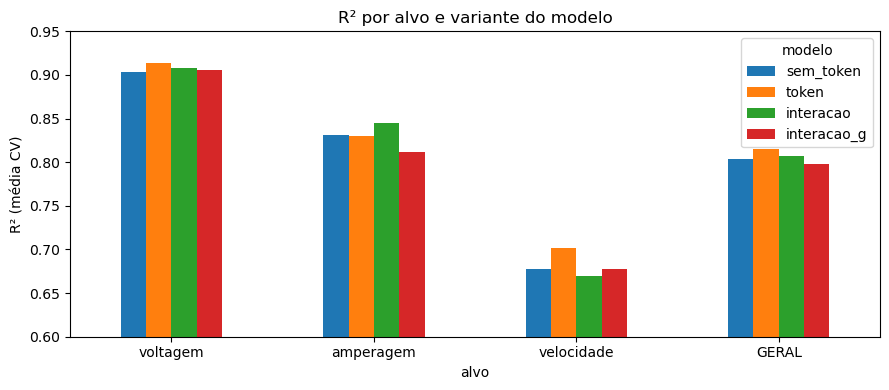

In [9]:
M = {
    "sem_token": {"voltagem": (0.0967, 0.2001, 0.9034), "amperagem": (0.1606, 0.2728, 0.8309),
                  "velocidade": (0.3290, 0.3090, 0.6775), "GERAL": (0.1954, 0.2606, 0.8039)},
    "token":     {"voltagem": (0.0866, 0.2009, 0.9140), "amperagem": (0.1621, 0.2801, 0.8301),
                  "velocidade": (0.3095, 0.3078, 0.7012), "GERAL": (0.1861, 0.2630, 0.8151)},
    "interacao": {"voltagem": (0.0930, 0.1981, 0.9079), "amperagem": (0.1481, 0.2654, 0.8444),
                  "velocidade": (0.3363, 0.3117, 0.6693), "GERAL": (0.1925, 0.2584, 0.8072)},
    "interacao_g": {"voltagem": (0.0951, 0.2130, 0.9058), "amperagem": (0.1813, 0.2953, 0.8121),
                    "velocidade": (0.3302, 0.3101, 0.6773), "GERAL": (0.2022, 0.2728, 0.7984)},
}
met = pd.DataFrame([{"modelo": m, "alvo": a, "MSE": v[0], "MAE": v[1], "R2": v[2]}
                    for m, d in M.items() for a, v in d.items()])

for metrica in ["R2", "MSE", "MAE"]:
    print(f"\n{metrica}")
    display(met.pivot(index="modelo", columns="alvo", values=metrica).loc[list(M)])

delta = met.pivot(index="modelo", columns="alvo", values="R2")
delta = (delta - delta.loc["sem_token"]).round(4).loc[list(M)]
print("\nΔR² vs sem_token")
display(delta)

alvos = ["voltagem", "amperagem", "velocidade", "GERAL"]
pv = met.pivot(index="alvo", columns="modelo", values="R2").loc[alvos, list(M)]
ax = pv.plot(kind="bar", figsize=(9, 4), ylim=(0.6, 0.95))
ax.set_ylabel("R² (média CV)"); ax.set_title("R² por alvo e variante do modelo")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Cuidados na leitura**
- As diferenças de R² geral entre as variantes são da ordem de 0,01. Sem o desvio entre folds (ou repetição com seeds diferentes) não dá para dizer se são reais ou ruído; guarde `std` por fold nos próximos treinos.
- Os embeddings validados aqui vêm de um único treino (`embeddings_filtered.csv`). Se o resultado variar entre seeds, a conclusão sobre o token também varia, então vale repetir o Mantel com embeddings de 3–5 seeds.
- Os materiais ausentes de um dos lados (impressos na seção 2) ficam fora de toda a análise.